# Entrenamiento de CNN con Transfer Learning
## Objetivos
- Baseline simple con transfer learning usando ResNet18 o VGG16,
- Entrenar solo la cabeza clasificadora (fine-tuning parcial),
- Hacer fine-tuning parcial o total según resultados,
- Guardar métricas por época,
- Guardar el mejor modelo según validación,
- Matriz de confusión y reporte de clasificación final,
- Accuracy, precision, recall y F1-score.

In [1]:
# Importaciones
import os

import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from torchvision import models
from torchvision import datasets
from torchvision import transforms as tfs

from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

from _bootstrap import setup
from src.vasijas.reporting import ProcessingReport

In [2]:
# Configuración general
PATHS = setup()
report = ProcessingReport()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BATCH_SIZE = 32
EPOCHS = 30
LR = 1e-3

NUM_WORKERS = min(8, os.cpu_count() or 1)
PIN_MEMORY = DEVICE.type == "cuda"
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.float16
USE_CHANNELS_LAST = DEVICE.type == "cuda"
ENABLE_MODEL_COMPILE = False

if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True
    torch.set_float32_matmul_precision("high")

IMG_SIZE = 224

FLIP_PROBABILITY = 0.5
SCALING_FACTOR_INTERVAL = (0.8, 1.)
ROTATION_DEGREES = (-15, 15)
PIXEL_FILL = (255, 255, 255)

SEED = 42

DATA_DIR = PATHS.DATA_CUADRADOS
MODEL_NAME = "resnet18"

print("Device:", DEVICE)
print(
    f"Config -> batch_size: {BATCH_SIZE}, workers: {NUM_WORKERS}, "
    f"pin_memory: {PIN_MEMORY}, amp: {USE_AMP}"
)

Device: cuda
Config -> batch_size: 32, workers: 8, pin_memory: True, amp: True


In [3]:
# Transformaciones
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transforms = tfs.Compose([
    tfs.Resize((IMG_SIZE, IMG_SIZE), interpolation=tfs.InterpolationMode.BILINEAR),
    tfs.RandomHorizontalFlip(p=FLIP_PROBABILITY),
    tfs.RandomRotation(degrees=ROTATION_DEGREES, fill=PIXEL_FILL),
    tfs.RandomAffine(degrees=0, scale=SCALING_FACTOR_INTERVAL, fill=PIXEL_FILL),
    tfs.ToTensor(),
    tfs.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

val_transforms = tfs.Compose([
    tfs.Resize((IMG_SIZE, IMG_SIZE), interpolation=tfs.InterpolationMode.BILINEAR),
    tfs.ToTensor(),
    tfs.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

test_transforms = val_transforms


class TransformSubset(Dataset):
    """Subset por indices que aplica transform al vuelo."""

    def __init__(self, dataset, indices, transform=None):
        self.dataset = dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        x, y = self.dataset[self.indices[i]]  # x es PIL si dataset base no tiene transform
        if self.transform is not None:
            x = self.transform(x)
        return x, y


# a) Dataset base SIN transformaciones
full_dataset = datasets.ImageFolder(DATA_DIR)

indices = np.arange(len(full_dataset))
labels = np.array(full_dataset.targets)

# train vs temp
train_idx, temp_idx, train_labels, temp_labels = train_test_split(
    indices,
    labels,
    test_size=0.30,
    stratify=labels,
    random_state=SEED
)

# val vs test
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=temp_labels,
    random_state=SEED
)

train_dataset = TransformSubset(full_dataset, train_idx, transform=train_transforms)
val_dataset = TransformSubset(full_dataset, val_idx, transform=val_transforms)
test_dataset = TransformSubset(full_dataset, test_idx, transform=test_transforms)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=NUM_WORKERS > 0,
    prefetch_factor=4 if NUM_WORKERS > 0 else None,
    drop_last=True,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=NUM_WORKERS > 0,
    prefetch_factor=4 if NUM_WORKERS > 0 else None,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    persistent_workers=NUM_WORKERS > 0,
    prefetch_factor=4 if NUM_WORKERS > 0 else None,
)

class_names = full_dataset.classes
NUM_CLASSES = len(class_names)

print("Clases:", class_names)
print(f"Split -> train: {len(train_dataset)}, val: {len(val_dataset)}, test: {len(test_dataset)}")

Clases: ['clase01', 'clase02', 'clase03', 'clase05', 'clase06', 'clase07', 'clase08', 'clase09', 'clase10', 'clase11']
Split -> train: 749, val: 161, test: 161


In [4]:
from torchvision.models import ResNet18_Weights


# 3. Visualización rápida (sanity check)
def show_batch(loader):
    images, labels = next(iter(loader))
    images = images[:8]
    labels = labels[:8]

    fig, axes = plt.subplots(1, 8, figsize=(16, 3))
    for i, ax in enumerate(axes):
        img = images[i].permute(1, 2, 0).numpy()
        ax.imshow(img.squeeze(), cmap="gray")
        ax.set_title(class_names[labels[i]])
        ax.axis("off")


# Modelo (reemplaza rama resnet18 en get_model)
def get_model(model_name, num_classes):
    if model_name == "resnet18":
        weights = ResNet18_Weights.DEFAULT  # equivalente a IMAGENET1K_V1
        model = models.resnet18(weights=weights, progress=True)

        for param in model.parameters():
            param.requires_grad = False

        model.fc = nn.Linear(model.fc.in_features, num_classes)

    elif model_name == "vgg16":
        model = models.vgg16(weights="IMAGENET1K_V1")
        for param in model.parameters():
            param.requires_grad = False
        model.classifier[6] = nn.Linear(model.classifier[6].in_features, num_classes)

    else:
        raise ValueError("Modelo no soportado")

    return model.to(DEVICE)


model = get_model(MODEL_NAME, NUM_CLASSES)
if USE_CHANNELS_LAST:
    model = model.to(memory_format=torch.channels_last)

if ENABLE_MODEL_COMPILE and hasattr(torch, "compile") and DEVICE.type == "cuda":
    model = torch.compile(model)

In [5]:
# 5. Funciones de 03.entrenamiento y validación
criterion = nn.CrossEntropyLoss()
scaler = torch.amp.GradScaler(device=DEVICE.type, enabled=USE_AMP)

# Optimizador (ajusta para entrenar solo lo descongelado)
optimizer = optim.Adam((p for p in model.parameters() if p.requires_grad), lr=LR)


def train_one_epoch(model, loader):
    model.train()
    total_loss = 0
    correct = 0

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=PIN_MEMORY)
        labels = labels.to(DEVICE, non_blocking=PIN_MEMORY)
        if USE_CHANNELS_LAST:
            images = images.to(memory_format=torch.channels_last)

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()

    acc = correct / len(loader.dataset)
    return total_loss / len(loader), acc


def validate(model, loader):
    model.eval()
    total_loss = 0
    correct = 0

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=PIN_MEMORY)
            labels = labels.to(DEVICE, non_blocking=PIN_MEMORY)
            if USE_CHANNELS_LAST:
                images = images.to(memory_format=torch.channels_last)

            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                outputs = model(images)
                loss = criterion(outputs, labels)

            total_loss += loss.item()
            _, preds = torch.max(outputs, 1)

            correct += (preds == labels).sum().item()

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = correct / len(loader.dataset)
    return total_loss / len(loader), acc, all_preds, all_labels

In [6]:
# 6. Loop de 03.entrenamiento
from datetime import datetime

train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(EPOCHS):

    momento_inicio = datetime.now();

    train_loss, train_acc = train_one_epoch(model, train_loader)
    val_loss, val_acc, preds, labels = validate(model, val_loader)

    momento_fin = datetime.now();
    tiempo_epoch = momento_fin - momento_inicio

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")
    print(f"Tiempo de epoch: {tiempo_epoch}")

Epoch 1/30
Train Loss: 1.8027 | Train Acc: 0.4286
Val Loss: 1.5646 | Val Acc: 0.5404
Tiempo de epoch: 0:00:07.861109
Epoch 2/30
Train Loss: 1.3733 | Train Acc: 0.5808
Val Loss: 1.2169 | Val Acc: 0.5652
Tiempo de epoch: 0:00:05.357068
Epoch 3/30
Train Loss: 1.1731 | Train Acc: 0.6142
Val Loss: 1.1364 | Val Acc: 0.6398
Tiempo de epoch: 0:00:05.311077
Epoch 4/30
Train Loss: 1.0297 | Train Acc: 0.6636
Val Loss: 0.9644 | Val Acc: 0.6708
Tiempo de epoch: 0:00:05.312913
Epoch 5/30
Train Loss: 0.9847 | Train Acc: 0.6836
Val Loss: 0.9386 | Val Acc: 0.6770
Tiempo de epoch: 0:00:05.473516
Epoch 6/30
Train Loss: 0.8959 | Train Acc: 0.7103
Val Loss: 0.9181 | Val Acc: 0.7267
Tiempo de epoch: 0:00:05.373174
Epoch 7/30
Train Loss: 0.8801 | Train Acc: 0.7116
Val Loss: 0.8780 | Val Acc: 0.7329
Tiempo de epoch: 0:00:05.343548
Epoch 8/30
Train Loss: 0.8260 | Train Acc: 0.7463
Val Loss: 0.8954 | Val Acc: 0.7019
Tiempo de epoch: 0:00:05.227448
Epoch 9/30
Train Loss: 0.7786 | Train Acc: 0.7463
Val Loss: 0.82

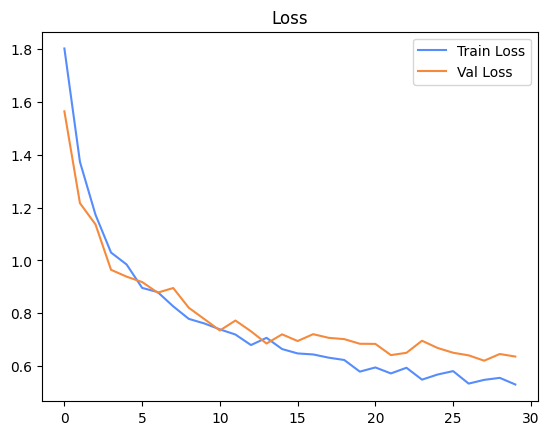

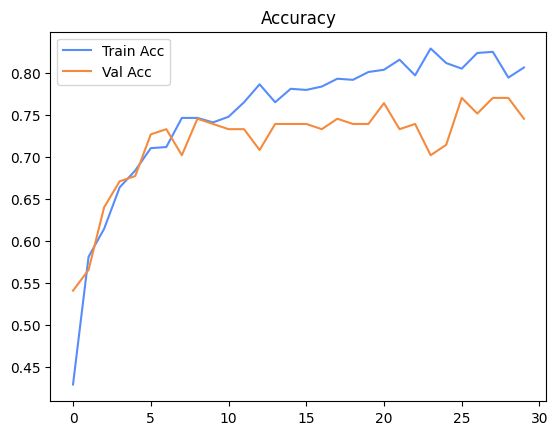

In [7]:
# 7. Curvas de 03.entrenamiento
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Val Loss")
plt.legend()
plt.title("Loss")
plt.show()

plt.plot(train_accs, label="Train Acc")
plt.plot(val_accs, label="Val Acc")
plt.legend()
plt.title("Accuracy")
plt.show()

Test Acc: 0.7205
              precision    recall  f1-score   support

     clase01       1.00      0.50      0.67         4
     clase02       0.00      0.00      0.00         7
     clase03       0.71      0.45      0.56        11
     clase05       0.30      0.88      0.45         8
     clase06       1.00      0.12      0.22         8
     clase07       0.67      0.57      0.62         7
     clase08       0.78      0.74      0.76        42
     clase09       0.00      0.00      0.00         3
     clase10       0.77      1.00      0.87        53
     clase11       1.00      0.72      0.84        18

    accuracy                           0.72       161
   macro avg       0.62      0.50      0.50       161
weighted avg       0.73      0.72      0.69       161



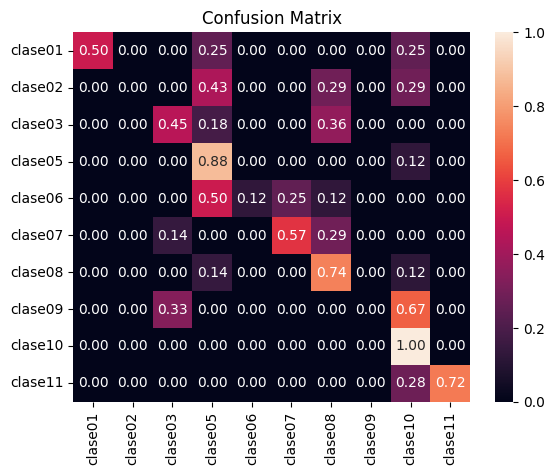

In [8]:
# 8. Evaluación final
_, test_acc, final_preds, final_labels = validate(model, test_loader)
print(f"Test Acc: {test_acc:.4f}")

all_label_ids = list(range(NUM_CLASSES))

print(
    classification_report(
        final_labels,
        final_preds,
        labels=all_label_ids,
        target_names=class_names,
        zero_division=0,
    )
)

cm = confusion_matrix(final_labels, final_preds, labels=all_label_ids, normalize='true')
sns.heatmap(cm, annot=True, fmt=".2f", xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.show()

In [9]:
# 9. Guardado del modelo
torch.save(model.state_dict(), PATHS.OUTPUT_MODELS / f"{MODEL_NAME}_final.pth")